# Project 3 -- RNN on resting-state fMRI time series

- Class: CSE 6389
- Name: John (chenxi) Song
- ID: 1002306479

# 1. Data Description


## 1. Data Description

Resting-state fMRI time-series data from 20 subjects:

- 10 Alzheimer's disease (AD) subjects
- 10 cognitively normal (CN) subjects

Each subject folder contains 101 fMRI timepoint files under `fmri_average_signal/`. Each file has shape: $(150, 1)$

- where the 150 values correspond to 150 brain regions of interest (ROIs).

The 101 files are ordered by timepoint and stacked together to form one subject-level sequence with shape: $(101, 150)$

  
- 101 = number of timepoints
- 150 = number of ROIs

Therefore, each subject is represented as a multivariate time series:

$$
X \in \mathbb{R}^{101 \times 150}
$$

Each row represents one timepoint, and each column represents the fMRI signal of one ROI across time.

The classification label is defined as:

$$
y =
\begin{cases}
1, & \text{AD} \\
0, & \text{CN}
\end{cases}
$$

## 1.1 Example of AD 1

In [7]:
import os
import glob
import numpy as np

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
DATA_ROOT = "/content/drive/MyDrive/6389_data/Project/Project3/6389Project3Data/"

AD1 = load_sequence("AD1")

print("Shape:", AD1.shape)
print("First timepoint shape:", AD1[0].shape)
print("ROI 0 time series shape:", AD1[:, 0].shape)

print("Shape:", AD1.shape)

print("Min:", AD1.min())
print("Max:", AD1.max())
print("Mean:", AD1.mean())
print("Std:", AD1.std())

print("Any NaN:", np.isnan(AD1).any())
print("Any Inf:", np.isinf(AD1).any())



Shape: (101, 150)
First timepoint shape: (150,)
ROI 0 time series shape: (101,)
Shape: (101, 150)
Min: -325.58475204779177
Max: 366.6443419298589
Mean: -3.0556364566889145
Std: 61.842107696107824
Any NaN: False
Any Inf: False


One subject, AD1, was first examined to verify the sequence structure and basic statistics. The sequence contained no NaN or infinite values before preprocessing. Each column represents the time course of one ROI across all 101 timepoints.

In [11]:
roi_mean = AD1.mean(axis=0)
roi_std = AD1.std(axis=0)

print("ROI mean shape:", roi_mean.shape)
print("ROI std shape:", roi_std.shape)

print("Minimum ROI std:", roi_std.min())
print("Maximum ROI std:", roi_std.max())

zero_var_rois = np.where(roi_std == 0)[0]
print("Zero-variance ROIs:", zero_var_rois)

ROI mean shape: (150,)
ROI std shape: (150,)
Minimum ROI std: 0.0
Maximum ROI std: 124.37249827022093
Zero-variance ROIs: [ 41 116]


Several individual ROI signals were plotted across the 101 timepoints. The signals changed smoothly over time rather than behaving like independent random values.

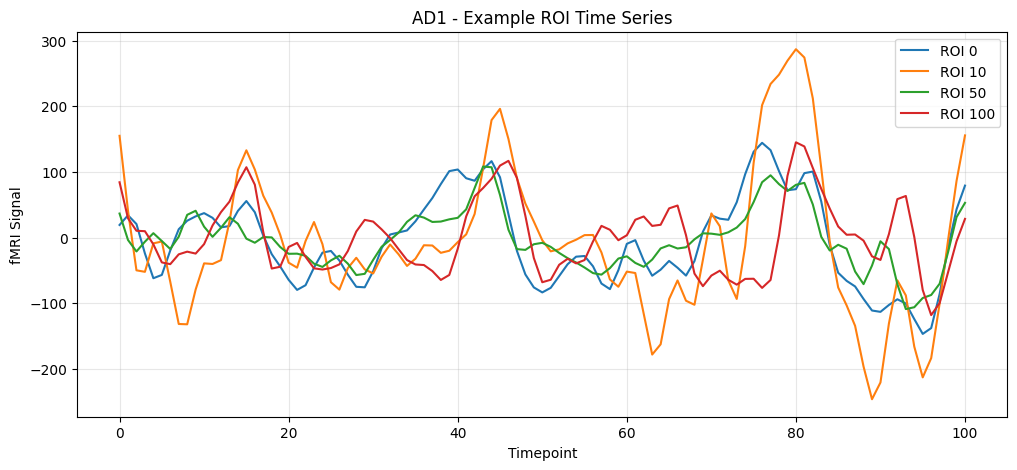

In [12]:
import matplotlib.pyplot as plt

time = np.arange(AD1.shape[0])

plt.figure(figsize=(12, 5))

for roi in [0, 10, 50, 100]:
    plt.plot(
        time,
        AD1[:, roi],
        label=f"ROI {roi}"
    )

plt.xlabel("Timepoint")
plt.ylabel("fMRI Signal")
plt.title("AD1 - Example ROI Time Series")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

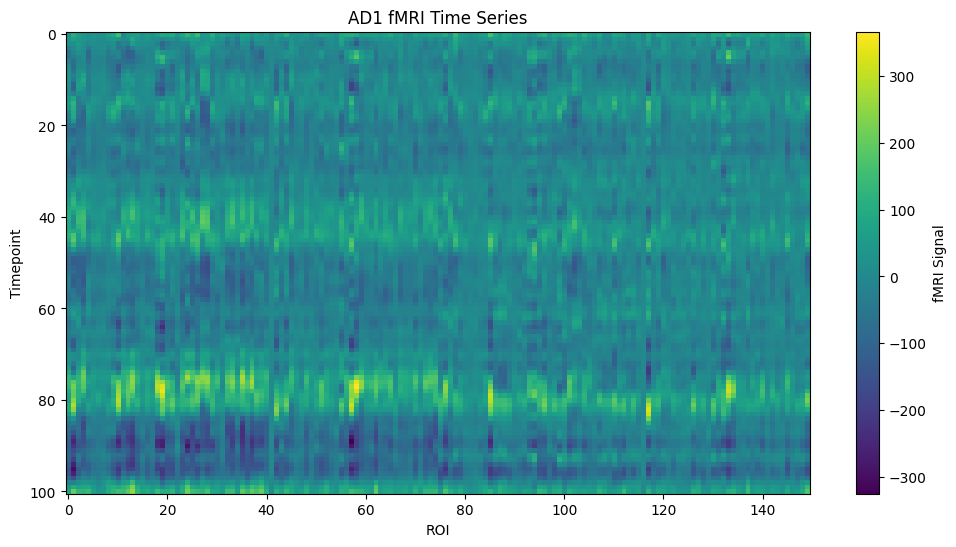

In [13]:
plt.figure(figsize=(12, 6))

plt.imshow(
    AD1,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="fMRI Signal")
plt.xlabel("ROI")
plt.ylabel("Timepoint")
plt.title("AD1 fMRI Time Series")

plt.show()

# 2. Data Preprocessing (EDA Analysis)
---

EDA Summary:

The exploratory analysis revealed three important characteristics of the dataset:

The fMRI data contains strong temporal structure, supporting the use of a recurrent model.

Signal scale differs substantially across subjects, with approximately a 5.97-fold difference between the largest and smallest subject standard deviations.

ROIs 41 and 116 have zero variance and would cause numerical problems during standard normalization.

Based on these findings, the next preprocessing stage will apply per-subject normalization across time while safely handling the two zero-variance ROIs.

## 2.1 Per-Subject Normalization
The mean and standard deviation of the complete fMRI sequence were calculated for each of the 20 subjects.


The subject-level standard deviation ranged from approximately: $26.05$ to:$155.58$

The ratio between the largest and smallest subject standard deviations was therefore approximately:

$$
\frac{155.58}{26.05} \approx 5.97
$$

This shows that subjects have substantially different signal scales. If the raw sequences were used directly for training, subjects with larger signal amplitudes could have a disproportionately large influence on the model.

**This observation motivates per-subject normalization before training the recurrent model.**

In [14]:
subjects = (
    [f"AD{i}" for i in range(1, 11)] +
    [f"CN{i}" for i in range(1, 11)]
)

sequences = {}

for subject in subjects:
    sequences[subject] = load_sequence(subject)


subject_stats = []

for subject in subjects:
    seq = sequences[subject]

    subject_stats.append({
        "subject": subject,
        "mean": seq.mean(),
        "std": seq.std()
    })

In [15]:
import pandas as pd

stats_df = pd.DataFrame(subject_stats)

stats_df

,subject,mean,std
0,AD1,-3.055636,61.842108
1,AD2,-0.469985,51.354851
2,AD3,2.220513,41.138346
3,AD4,-0.251020,64.452354
4,AD5,0.483273,30.039915
5,AD6,-3.263983,83.856357
6,AD7,3.365738,155.576707
7,AD8,0.357807,52.045478
8,AD9,-0.949168,27.785621
9,AD10,-1.621404,63.005907


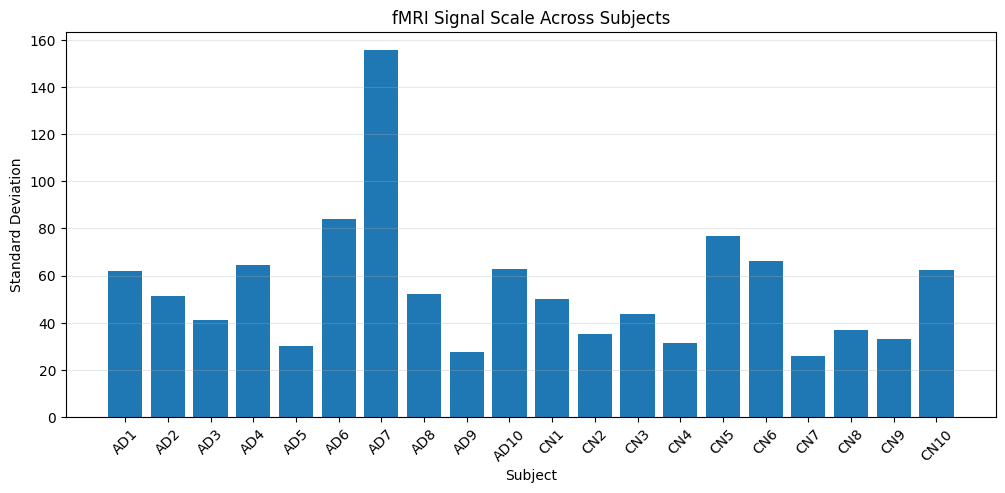

In [16]:
plt.figure(figsize=(12, 5))

plt.bar(
    stats_df["subject"],
    stats_df["std"]
)

plt.xlabel("Subject")
plt.ylabel("Standard Deviation")
plt.title("fMRI Signal Scale Across Subjects")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

The standard deviation of every ROI was calculated across the 101 timepoints for all subjects.

Two ROIs consistently had zero variance:

- ROI 41

- ROI 116

Their signals remained constant across the full sequence.

Therefore, the preprocessing procedure must explicitly handle zero-variance ROIs before the data is passed into the RNN.

In [17]:
constant_roi_results = []

for subject in subjects:

    seq = sequences[subject]

    roi_std = seq.std(axis=0)

    zero_var_rois = np.where(
        roi_std == 0
    )[0]

    constant_roi_results.append({
        "subject": subject,
        "zero_var_rois": zero_var_rois.tolist()
    })

constant_roi_results

[{'subject': 'AD1', 'zero_var_rois': [41, 116]},
 {'subject': 'AD2', 'zero_var_rois': [41, 116]},
 {'subject': 'AD3', 'zero_var_rois': [41, 116]},
 {'subject': 'AD4', 'zero_var_rois': [41, 116]},
 {'subject': 'AD5', 'zero_var_rois': [41, 116]},
 {'subject': 'AD6', 'zero_var_rois': [41, 116]},
 {'subject': 'AD7', 'zero_var_rois': [41, 116]},
 {'subject': 'AD8', 'zero_var_rois': [41, 116]},
 {'subject': 'AD9', 'zero_var_rois': [41, 116]},
 {'subject': 'AD10', 'zero_var_rois': [41, 116]},
 {'subject': 'CN1', 'zero_var_rois': [41, 116]},
 {'subject': 'CN2', 'zero_var_rois': [41, 116]},
 {'subject': 'CN3', 'zero_var_rois': [41, 116]},
 {'subject': 'CN4', 'zero_var_rois': [41, 116]},
 {'subject': 'CN5', 'zero_var_rois': [41, 116]},
 {'subject': 'CN6', 'zero_var_rois': [41, 116]},
 {'subject': 'CN7', 'zero_var_rois': [41, 116]},
 {'subject': 'CN8', 'zero_var_rois': [41, 116]},
 {'subject': 'CN9', 'zero_var_rois': [41, 116]},
 {'subject': 'CN10', 'zero_var_rois': [41, 116]}]

To confirm the presence of temporal structure, lag-1 autocorrelation was calculated for several example ROIs:

In [18]:
def lag1_autocorr(x):
    return np.corrcoef(
        x[:-1],
        x[1:]
    )[0, 1]

for roi in [0, 10, 50, 100]:
    r = lag1_autocorr(
        sequences["AD1"][:, roi]
    )

    print(
        f"ROI {roi}: "
        f"lag-1 autocorrelation = {r:.3f}"
    )

ROI 0: lag-1 autocorrelation = 0.929
ROI 10: lag-1 autocorrelation = 0.898
ROI 50: lag-1 autocorrelation = 0.900
ROI 100: lag-1 autocorrelation = 0.850


These high positive autocorrelation values indicate that nearby timepoints are strongly related. This supports the use of a recurrent neural network, since an RNN can model dependencies across the temporal sequence.

# 3. Input Data Preparation & Modeling

## 3.1 Normlization Per Subject


Exploratory analysis showed that the fMRI signal scale varies substantially across subjects. The subject-level standard deviation ranged from approximately 26.05 to 155.58, giving a scale difference of about 5.97×.

To reduce this subject-to-subject scale variation, each subject was normalized independently using z-score normalization.

For each ROI \(r\), the signal across the 101 timepoints was normalized as:

$$
z_{t,r} = \frac{x_{t,r} - \mu_r}{\sigma_r}
$$

where:

- $x_{t,r}$ is the original fMRI signal at timepoint $t$ for ROI $r$
- $\mu_r$ is the mean of ROI \(r\) across the 101 timepoints
- $\sigma_r$ is the standard deviation of ROI \(r\) across the 101 timepoints

This transformation centers each ROI around zero and scales its variation to approximately one standard deviation.

Normalization was performed separately for each subject so that the RNN focuses more on relative temporal changes in the fMRI signals rather than differences in raw signal magnitude between subjects.

The sequence shape remained unchanged:

$
(101,150) \rightarrow (101,150)
$

After normalization, the overall subject means were approximately 0 and the overall standard deviations were approximately 0.993. The value is slightly below 1 because two ROIs have zero variance and are handled separately in the next preprocessing step.


ROI 41 and ROI 116 have zero variance across all 101 timepoints for every subject. `std[std == 0] = 1`

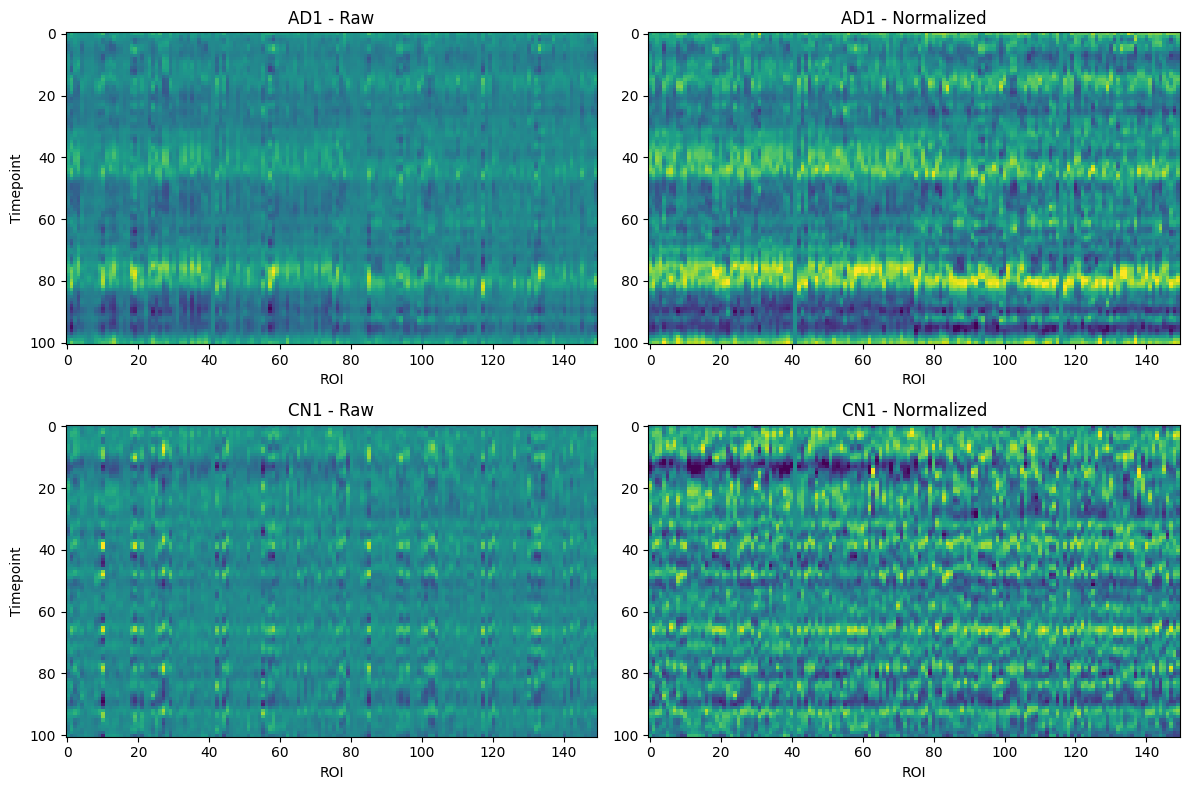

In [19]:
fmri_processed = {}

for subject in subjects:
    sequence = sequences[subject]

    fmri_processed[subject] = normalize_sequence(
        sequence
    )


display_subjects = ["AD1", "CN1"]

fig, axes = plt.subplots(
    len(display_subjects),
    2,
    figsize=(12, 8)
)

for i, subject in enumerate(display_subjects):

    raw = sequences[subject]
    normalized = fmri_processed[subject]

    # Raw
    axes[i, 0].imshow(
        raw,
        aspect="auto",
        cmap="viridis"
    )

    axes[i, 0].set_title(f"{subject} - Raw")
    axes[i, 0].set_ylabel("Timepoint")

    # Normalized
    axes[i, 1].imshow(
        normalized,
        aspect="auto",
        cmap="viridis",
        vmin=-3,
        vmax=3
    )

    axes[i, 1].set_title(f"{subject} - Normalized")

    axes[i, 0].set_xlabel("ROI")
    axes[i, 1].set_xlabel("ROI")

plt.tight_layout()
plt.show()

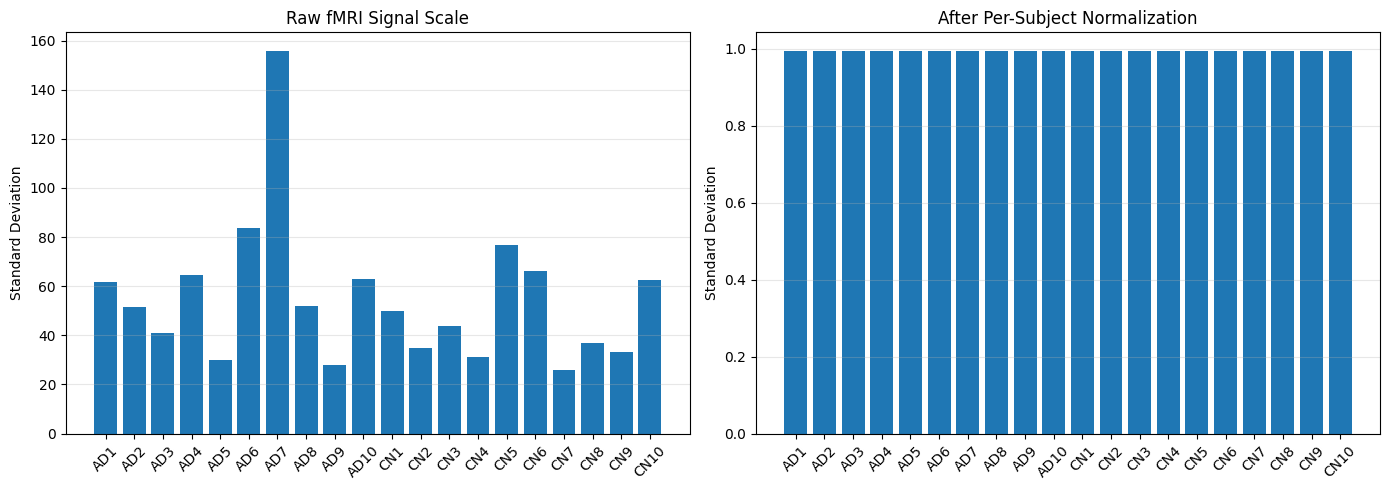

In [20]:
raw_std = [
    sequences[subject].std()
    for subject in subjects
]

normalized_std = [
    fmri_processed[subject].std()
    for subject in subjects
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Raw
axes[0].bar(
    subjects,
    raw_std
)

axes[0].set_title("Raw fMRI Signal Scale")
axes[0].set_ylabel("Standard Deviation")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y", alpha=0.3)

# Normalized
axes[1].bar(
    subjects,
    normalized_std
)

axes[1].set_title("After Per-Subject Normalization")
axes[1].set_ylabel("Standard Deviation")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 3.2 Input Data Preparation

- 5 straigtfied fold with seed 42

### 3.2.1 Data Split


```
Fold: 1
Train: ['AD1', 'AD3', 'AD5', 'AD6', 'AD7', 'AD8', 'AD9', 'AD10', 'CN3', 'CN4', 'CN5', 'CN6', 'CN7', 'CN8', 'CN9', 'CN10']
Test: ['AD2', 'AD4', 'CN1', 'CN2']

Fold: 2
Train: ['AD1', 'AD2', 'AD3', 'AD4', 'AD5', 'AD7', 'AD8', 'AD10', 'CN1', 'CN2', 'CN3', 'CN4', 'CN6', 'CN7', 'CN8', 'CN9']
Test: ['AD6', 'AD9', 'CN5', 'CN10']

Fold: 3
Train: ['AD1', 'AD2', 'AD4', 'AD5', 'AD6', 'AD7', 'AD9', 'AD10', 'CN1', 'CN2', 'CN3', 'CN5', 'CN7', 'CN8', 'CN9', 'CN10']
Test: ['AD3', 'AD8', 'CN4', 'CN6']

Fold: 4
Train: ['AD1', 'AD2', 'AD3', 'AD4', 'AD6', 'AD7', 'AD8', 'AD9', 'CN1', 'CN2', 'CN3', 'CN4', 'CN5', 'CN6', 'CN8', 'CN10']
Test: ['AD5', 'AD10', 'CN7', 'CN9']

Fold: 5
Train: ['AD2', 'AD3', 'AD4', 'AD5', 'AD6', 'AD8', 'AD9', 'AD10', 'CN1', 'CN2', 'CN4', 'CN5', 'CN6', 'CN7', 'CN9', 'CN10']
Test: ['AD1', 'AD7', 'CN3', 'CN8']


```

In [21]:
from sklearn.model_selection import StratifiedKFold

labels = [
    1 if subject.startswith("AD") else 0
    for subject in subjects
]

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = []

for fold, (train_idx, test_idx) in enumerate(
    skf.split(subjects, labels)
):

    train_subjects = [
        subjects[i]
        for i in train_idx
    ]

    test_subjects = [
        subjects[i]
        for i in test_idx
    ]

    folds.append({
        "fold": fold + 1,
        "train_subjects": train_subjects,
        "test_subjects": test_subjects
    })

In [22]:
for fold in folds:
  print("Fold:",fold["fold"])
  print("Train:",fold["train_subjects"])
  print("Test:",fold["test_subjects"])
  print()

Fold: 1
Train: ['AD1', 'AD3', 'AD5', 'AD6', 'AD7', 'AD8', 'AD9', 'AD10', 'CN3', 'CN4', 'CN5', 'CN6', 'CN7', 'CN8', 'CN9', 'CN10']
Test: ['AD2', 'AD4', 'CN1', 'CN2']

Fold: 2
Train: ['AD1', 'AD2', 'AD3', 'AD4', 'AD5', 'AD7', 'AD8', 'AD10', 'CN1', 'CN2', 'CN3', 'CN4', 'CN6', 'CN7', 'CN8', 'CN9']
Test: ['AD6', 'AD9', 'CN5', 'CN10']

Fold: 3
Train: ['AD1', 'AD2', 'AD4', 'AD5', 'AD6', 'AD7', 'AD9', 'AD10', 'CN1', 'CN2', 'CN3', 'CN5', 'CN7', 'CN8', 'CN9', 'CN10']
Test: ['AD3', 'AD8', 'CN4', 'CN6']

Fold: 4
Train: ['AD1', 'AD2', 'AD3', 'AD4', 'AD6', 'AD7', 'AD8', 'AD9', 'CN1', 'CN2', 'CN3', 'CN4', 'CN5', 'CN6', 'CN8', 'CN10']
Test: ['AD5', 'AD10', 'CN7', 'CN9']

Fold: 5
Train: ['AD2', 'AD3', 'AD4', 'AD5', 'AD6', 'AD8', 'AD9', 'AD10', 'CN1', 'CN2', 'CN4', 'CN5', 'CN6', 'CN7', 'CN9', 'CN10']
Test: ['AD1', 'AD7', 'CN3', 'CN8']



### 3.2.2 Dataset and DataLoader

In [23]:
import torch
from torch.utils.data import Dataset, DataLoader


class FMRIDataset(Dataset):

    def __init__(
        self,
        subjects,
        fmri_processed
    ):
        self.subjects = subjects
        self.fmri_processed = fmri_processed

    def __len__(self):
        return len(self.subjects)

    def __getitem__(self, idx):

        subject = self.subjects[idx]

        X = torch.tensor(
            self.fmri_processed[subject],
            dtype=torch.float32
        )

        y = torch.tensor(
            1 if subject.startswith("AD") else 0,
            dtype=torch.long
        )

        return X, y, subject

In [24]:
fold = folds[0]

train_dataset = FMRIDataset(
    fold["train_subjects"],
    fmri_processed
)

test_dataset = FMRIDataset(
    fold["test_subjects"],
    fmri_processed
)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False
)

In [25]:
X_batch, y_batch, subject_batch = next(
    iter(train_loader)
)

print("X shape:", X_batch.shape)
print("y shape:", y_batch.shape)
print("Subjects:", subject_batch)

X shape: torch.Size([2, 101, 150])
y shape: torch.Size([2])
Subjects: ('AD5', 'AD1')


## 3.3 Modeling


### 3.3.1 Baseline with Logistic regression

A logistic regression classifier was used as a baseline model that ignores temporal order.

For each subject, the mean and standard deviation of every ROI were calculated across the 101 timepoints: $300 \text{ features}$

The baseline therefore converts each full time series into a fixed 300-dimensional feature vector.

Raw fMRI sequences were used for baseline feature extraction because extracting mean and standard deviation after per-ROI z-score normalization would produce values close to 0 and 1 for nearly every live ROI.

Feature scaling was fitted using only the training subjects within each fold before logistic regression training.

The baseline used the same fixed 5-fold splits and the same evaluation procedure as the RNN.

In [44]:
def extract_baseline_features(sequence):

    roi_mean = sequence.mean(axis=0)
    roi_std = sequence.std(axis=0)

    return np.concatenate([
        roi_mean,
        roi_std
    ])


### 3.3.2 RNN
```
(2, 101, 150)
      ↓
RNN reads 101 timepoints
      ↓
hidden representation = 64
      ↓
Linear(64 → 2)
      ↓
CN / AD
```


The model was trained using:

- CrossEntropyLoss

- Adam optimizer

- learning rate = 0.001

- batch size = 2

- 30 epochs

For each random seed, a new RNN was trained independently on all five folds.

In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [28]:
class RNNClassifier(nn.Module):

    def __init__(
        self,
        input_size=150,
        hidden_size=64,
        num_layers=1,
        num_classes=2
    ):

        super().__init__()

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.classifier = nn.Linear(
            hidden_size,
            num_classes
        )

    def forward(self, X):

        output, hidden = self.rnn(X)

        # Last hidden state
        H = hidden[-1]

        logits = self.classifier(H)

        return logits

In [29]:
model = RNNClassifier()

X_batch, y_batch, subjects_batch = next(
    iter(train_loader)
)

output = model(X_batch)

print("Input shape:", X_batch.shape)
print("Output shape:", output.shape)
print("Labels:", y_batch)
print("Output:", output)

Input shape: torch.Size([2, 101, 150])
Output shape: torch.Size([2, 2])
Labels: tensor([0, 1])
Output: tensor([[-0.2883, -0.6736],
        [ 0.3908,  0.2177]], grad_fn=<AddmmBackward0>)


# 4. Training Model and Experiment

```
                     SAME
        fixed 5 folds + same 5 seeds
                     ↓
        ┌─────────────────────────┐
        │                         │
 Logistic Regression             RNN
 raw sequence                 normalized sequence
 ↓                            ↓
 mean/std → 300 features      (101,150)
 ↓                            ↓
 LogisticRegression           RNNClassifier
        │                         │
        └──────────┬──────────────┘
                   ↓
          SAME evaluation
 y_true / y_pred / y_prob
                   ↓
        calculate_metrics()


```

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader

seeds = [42, 123, 2026, 7, 99]

## 4.1 Baseline Logisc

In [ ]:
baseline_features = {}

for subject in subjects:
    baseline_features[subject] = (
        extract_baseline_features(
            sequences[subject]
        )
    )


In [47]:
baseline_results_df = run_experiment(
    model_type="baseline",
    seeds=seeds
)

baseline_results_df


BASELINE | Seed 42

========== Fold 1 ==========
Fold 1 Accuracy: 0.750

========== Fold 2 ==========
Fold 2 Accuracy: 0.750

========== Fold 3 ==========
Fold 3 Accuracy: 0.500

========== Fold 4 ==========
Fold 4 Accuracy: 0.500

========== Fold 5 ==========
Fold 5 Accuracy: 1.000

BASELINE | Seed 123

========== Fold 1 ==========
Fold 1 Accuracy: 0.750

========== Fold 2 ==========
Fold 2 Accuracy: 0.750

========== Fold 3 ==========
Fold 3 Accuracy: 0.500

========== Fold 4 ==========
Fold 4 Accuracy: 0.500

========== Fold 5 ==========
Fold 5 Accuracy: 1.000

BASELINE | Seed 2026

========== Fold 1 ==========
Fold 1 Accuracy: 0.750

========== Fold 2 ==========
Fold 2 Accuracy: 0.750

========== Fold 3 ==========
Fold 3 Accuracy: 0.500

========== Fold 4 ==========
Fold 4 Accuracy: 0.500

========== Fold 5 ==========
Fold 5 Accuracy: 1.000

BASELINE | Seed 7

========== Fold 1 ==========
Fold 1 Accuracy: 0.750

========== Fold 2 ==========
Fold 2 Accuracy: 0.750

========== Fold 

,seed,accuracy,f1,auc,sensitivity,specificity
0,42,0.7,0.666667,0.65,0.6,0.8
1,123,0.7,0.666667,0.65,0.6,0.8
2,2026,0.7,0.666667,0.65,0.6,0.8
3,7,0.7,0.666667,0.65,0.6,0.8
4,99,0.7,0.666667,0.65,0.6,0.8


## 4.2 RNN training

In [48]:
rnn_results_df = run_experiment(
    model_type="rnn",
    seeds=seeds
)

rnn_results_df


RNN | Seed 42

========== Fold 1 ==========
Epoch   1/30 | Loss: 0.6363
Epoch   5/30 | Loss: 0.1982
Epoch  10/30 | Loss: 0.0374
Epoch  15/30 | Loss: 0.0122
Epoch  20/30 | Loss: 0.0064
Epoch  25/30 | Loss: 0.0041
Epoch  30/30 | Loss: 0.0029
Fold 1 Accuracy: 0.750

========== Fold 2 ==========
Epoch   1/30 | Loss: 0.6420
Epoch   5/30 | Loss: 0.1482
Epoch  10/30 | Loss: 0.0224
Epoch  15/30 | Loss: 0.0089
Epoch  20/30 | Loss: 0.0053
Epoch  25/30 | Loss: 0.0036
Epoch  30/30 | Loss: 0.0026
Fold 2 Accuracy: 0.000

========== Fold 3 ==========
Epoch   1/30 | Loss: 0.7165
Epoch   5/30 | Loss: 0.2133
Epoch  10/30 | Loss: 0.0402
Epoch  15/30 | Loss: 0.0144
Epoch  20/30 | Loss: 0.0077
Epoch  25/30 | Loss: 0.0051
Epoch  30/30 | Loss: 0.0036
Fold 3 Accuracy: 0.500

========== Fold 4 ==========
Epoch   1/30 | Loss: 0.6776
Epoch   5/30 | Loss: 0.2204
Epoch  10/30 | Loss: 0.0480
Epoch  15/30 | Loss: 0.0178
Epoch  20/30 | Loss: 0.0091
Epoch  25/30 | Loss: 0.0057
Epoch  30/30 | Loss: 0.0039
Fold 4 Accur

,seed,accuracy,f1,auc,sensitivity,specificity
0,42,0.40,0.400000,0.46,0.4,0.4
1,123,0.55,0.571429,0.48,0.6,0.5
2,2026,0.60,0.600000,0.57,0.6,0.6
3,7,0.45,0.476190,0.39,0.5,0.4
4,99,0.35,0.380952,0.39,0.4,0.3


# 5. Evaluation

For each model, predictions from all five test folds were combined so that every subject contributed one out-of-fold prediction.

The following metrics were calculated:

- Accuracy

- F1 score

- AUROC

- Sensitivity

- Specificity


ROC curves were calculated from the combined out-of-fold prediction probabilities rather than from individual 4-subject folds.

Performance across the five seeds was summarized using the mean and 95% confidence interval.


| |Baseline|	RNN|
|--|--|--|
|accuracy|	0.700 ± 0.000|	0.470 ± 0.129|
|f1|	0.667 ± 0.000|	0.486 ± 0.122|
|auc|	0.650 ± 0.000	|0.458 ± 0.093|
|sensitivity|	0.600 ± 0.000	|0.500 ± 0.124|
|specificity|	0.800 ± 0.000|	0.440 ± 0.142|


In [54]:
from sklearn.metrics import (accuracy_score,f1_score,roc_auc_score, confusion_matrix)

In [53]:
from scipy.stats import t
import numpy as np
import pandas as pd

metrics = ["accuracy", "f1", "auc", "sensitivity", "specificity"]

def summary_ci(df):
    result = {}

    for metric in metrics:
        mean = df[metric].mean()
        sd = df[metric].std()
        n = len(df)

        margin = t.ppf(0.975, n - 1) * sd / np.sqrt(n)

        result[metric] = f"{mean:.3f} ± {margin:.3f}"

    return result

In [55]:
comparison_table = pd.DataFrame({
    "Baseline": summary_ci(baseline_results_df),
    "RNN": summary_ci(rnn_results_df)
})

comparison_table

,Baseline,RNN
accuracy,0.700 ± 0.000,0.470 ± 0.129
f1,0.667 ± 0.000,0.486 ± 0.122
auc,0.650 ± 0.000,0.458 ± 0.093
sensitivity,0.600 ± 0.000,0.500 ± 0.124
specificity,0.800 ± 0.000,0.440 ± 0.142


# 6. Conclusion


This project evaluated whether temporal resting-state fMRI information could be used to classify Alzheimer's disease and cognitively normal subjects.

Exploratory analysis identified three important properties of the dataset:

1. fMRI signals contain strong temporal dependence.

2. Raw signal scale differs substantially across subjects.

3. ROI 41 and ROI 116 have zero temporal variance.

These observations motivated per-subject z-score normalization with explicit handling of zero-variance ROIs.

Two classification approaches were compared using identical fixed stratified 5-fold cross-validation splits. Logistic regression used per-ROI mean and standard deviation features and therefore ignored time order, while the RNN directly processed the normalized ($101 \times 150$) temporal sequence.

Despite having access to temporal information, the RNN did not outperform the simpler baseline. Logistic regression achieved an accuracy of approximately 0.70 compared with 0.47 for the RNN.

These results suggest that, for this small dataset, simple statistical summaries provide more reliable discriminative information than a recurrent model attempting to learn temporal representations directly.

The result does not necessarily indicate that temporal fMRI information is uninformative. Instead, the limited sample size of only 20 subjects likely makes training a recurrent neural network unstable. A substantially larger dataset would be needed to determine whether recurrent models can effectively exploit temporal fMRI dynamics for AD classification.

# Appendix I - Coding

In [4]:
def load_sequence(subject):

    signal_dir = os.path.join(
        DATA_ROOT,
        subject,
        "fmri_average_signal"
    )

    files = glob.glob(
        os.path.join(
            signal_dir,
            "raw_fmri_feature_matrix_*.npy"
        )
    )

    files.sort(
        key=lambda path:
        int(
            os.path.basename(path)
            .split("_")[-1]
            .replace(".npy", "")
        )
    )

    sequence = np.stack(
        [np.load(file).ravel() for file in files],
        axis=0
    )

    return sequence

In [42]:
def normalize_sequence(sequence):

    mean = sequence.mean(axis=0)
    std = sequence.std(axis=0)

    # Prevent division by zero
    std[std == 0] = 1

    normalized = (sequence - mean) / std

    return normalized


def extract_baseline_features(sequence):

    roi_mean = sequence.mean(axis=0)
    roi_std = sequence.std(axis=0)

    features = np.concatenate([
        roi_mean,
        roi_std
    ])

    return features



In [40]:
import random


def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

In [39]:
def train_one_fold(model_type,train_subjects,seed, num_epochs=30, batch_size=2):

    set_seed(seed)

    # ==================================
    # Logistic Regression
    # ==================================

    if model_type == "baseline":
        X_train = np.array([
            extract_baseline_features(
                sequences[s]
            )
            for s in train_subjects
        ])

        y_train = np.array([
            1 if s.startswith("AD") else 0
            for s in train_subjects
        ])

        scaler = StandardScaler()

        X_train = scaler.fit_transform(X_train)

        model = LogisticRegression(max_iter=1000,random_state=seed)

        model.fit(X_train, y_train)

        return model, scaler


    # ==================================
    # RNN
    # ==================================

    if model_type == "rnn":

        train_dataset = FMRIDataset(
            train_subjects,
            fmri_processed
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True
        )

        model = RNNClassifier()

        criterion = nn.CrossEntropyLoss()

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=0.001
        )

        for epoch in range(num_epochs):
            model.train()
            total_loss = 0

            for X, y, _ in train_loader:
                optimizer.zero_grad()
                output = model(X)
                loss = criterion(output,y)

                loss.backward()
                optimizer.step()

                total_loss += loss.item()

            avg_loss = (
                total_loss /
                len(train_loader)
            )

            if (
                epoch == 0 or
                (epoch + 1) % 5 == 0
            ):

                print(
                    f"Epoch {epoch + 1:3d}/{num_epochs} "
                    f"| Loss: {avg_loss:.4f}"
                )

        return model, None

In [38]:
def evaluate_one_fold(
    model_type,
    model,
    scaler,
    test_subjects,
    batch_size=2
):

    # ==================================
    # Logistic Regression
    # ==================================

    if model_type == "baseline":

        X_test = np.array([
            extract_baseline_features(
                sequences[s]
            )
            for s in test_subjects
        ])

        y_true = np.array([
            1 if s.startswith("AD") else 0
            for s in test_subjects
        ])

        X_test = scaler.transform(
            X_test
        )

        y_pred = model.predict(
            X_test
        )

        y_prob = model.predict_proba(
            X_test
        )[:, 1]

        return (
            test_subjects,
            y_true.tolist(),
            y_pred.tolist(),
            y_prob.tolist()
        )


    # ==================================
    # RNN
    # ==================================

    if model_type == "rnn":

        test_dataset = FMRIDataset(
            test_subjects,
            fmri_processed
        )

        test_loader = DataLoader(
            test_dataset,
            batch_size=batch_size,
            shuffle=False
        )

        model.eval()

        subjects_out = []
        y_true = []
        y_pred = []
        y_prob = []

        with torch.no_grad():

            for X, y, subject in test_loader:

                output = model(X)

                probabilities = torch.softmax(
                    output,
                    dim=1
                )

                predictions = torch.argmax(
                    output,
                    dim=1
                )

                subjects_out.extend(
                    subject
                )

                y_true.extend(
                    y.tolist()
                )

                y_pred.extend(
                    predictions.tolist()
                )

                y_prob.extend(
                    probabilities[:, 1].tolist()
                )

        return (
            subjects_out,
            y_true,
            y_pred,
            y_prob
        )

In [37]:
def run_one_seed(
    model_type,
    seed,
    num_epochs=30
):

    all_subjects = []
    all_true = []
    all_pred = []
    all_prob = []

    for fold in folds:

        print(
            f"\n========== Fold {fold['fold']} =========="
        )

        model, scaler = train_one_fold(
            model_type=model_type,
            train_subjects=fold["train_subjects"],
            seed=seed,
            num_epochs=num_epochs
        )

        (
            subjects_fold,
            true_fold,
            pred_fold,
            prob_fold
        ) = evaluate_one_fold(
            model_type=model_type,
            model=model,
            scaler=scaler,
            test_subjects=fold["test_subjects"]
        )

        fold_accuracy = accuracy_score(
            true_fold,
            pred_fold
        )

        print(
            f"Fold {fold['fold']} "
            f"Accuracy: {fold_accuracy:.3f}"
        )

        all_subjects.extend(
            subjects_fold
        )

        all_true.extend(
            true_fold
        )

        all_pred.extend(
            pred_fold
        )

        all_prob.extend(
            prob_fold
        )

    metrics = calculate_metrics(
        all_true,
        all_pred,
        all_prob
    )

    return (
        all_subjects,
        all_true,
        all_pred,
        all_prob,
        metrics
    )

In [36]:
def run_experiment(
    model_type,
    seeds
):

    results = []

    for seed in seeds:

        print(
            f"\n=============================="
        )

        print(
            f"{model_type.upper()} | Seed {seed}"
        )

        print(
            "=============================="
        )

        (
            subjects_out,
            y_true,
            y_pred,
            y_prob,
            metrics
        ) = run_one_seed(
            model_type=model_type,
            seed=seed
        )

        results.append({
            "seed": seed,
            "accuracy": metrics["accuracy"],
            "f1": metrics["f1"],
            "auc": metrics["auc"],
            "sensitivity": metrics["sensitivity"],
            "specificity": metrics["specificity"]
        })

    return pd.DataFrame(results)

In [ ]:
def calculate_metrics(y_true,y_pred,y_prob):

    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    return {
        "accuracy": accuracy,
        "f1": f1,
        "auc": auc,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "confusion_matrix": cm
    }